In [1]:
import uproot
import pandas
import numpy as np
import os

from scipy import interpolate
import scipy

import matplotlib.pyplot as plt

uproot.__version__

'5.0.8'

In [2]:
## loading the data ##
# Define the folder path
opticsPath = "../g4PDEsim/dataOptics/"
scintPath = "../g4PDEsim/data_cf4_scint/"
rootPath = "../outputs/"

In [3]:
fileAir = uproot.open(os.path.join(rootPath, "air_N1e5_200-1200nm_0-60deg.root"))
fileCF4 = uproot.open(os.path.join(rootPath, "lcf4_N1e5_200-1200nm_0-60deg.root"))

ttAir = fileAir["simOutput"]
ttcf4 = fileCF4["simOutput"]


# Define the column names
column_names = ["fNphoton", "fPhotonWln", "fAngle", "fNonWindow", "fNonSurface", "fNonBulk", "fNinBulk"]
dfair = ttAir.arrays(library="pd")
print(dfair.head(5))
dfair["eff"] = dfair["fNinBulk"]/dfair["fNphoton"]

dfcf4 = ttcf4.arrays(library="pd")
dfcf4["eff"] = dfcf4["fNinBulk"]/dfcf4["fNphoton"]

# print(type(df))
# print(df.columns)

angles = dfair['fAngle'].unique()
print(angles)


   fNphoton  fPhotonWln     fAngle  fNonWindow  fNonSurface  fNonBulk   
0    100000  199.974514   0.000000        1087          556       242  \
1    100000  199.974514  33.600021        1210          609       284   
2    100000  199.974514  48.200017        2062          904       406   
3    100000  199.974514  60.000140        4814         2166       784   
4    100000  210.142709   0.000000        8582         3834      1533   

   fNinBulk  
0     98115  
1     97897  
2     96628  
3     92236  
4     86051  
[ 0.         33.60002128 48.20001722 60.00014031]


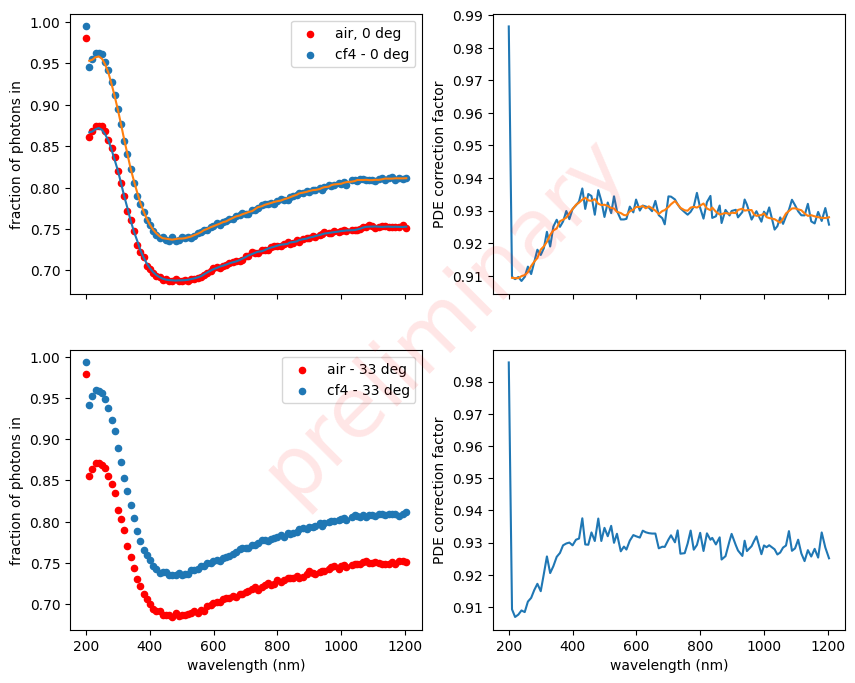

In [4]:
dfAir_a0 = dfair[dfair["fAngle"] == angles[0]]
dfcf4_a0 = dfcf4[dfcf4["fAngle"] == angles[0]]

dfAir_a33 = dfair[dfair["fAngle"] == angles[1]]
dfcf4_a33 = dfcf4[dfcf4["fAngle"] == angles[1]]

# Plot the data frames on the same canvas
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, sharex='all', figsize=(10, 8))

dfAir_a0.plot(x="fPhotonWln", y="eff", kind="scatter", color='r', label='air, 0 deg', ax = ax1)
dfcf4_a0.plot(x="fPhotonWln", y="eff", kind="scatter", label="cf4 - 0 deg", ax = ax1)

ax2.plot(dfAir_a0["fPhotonWln"], dfAir_a0["eff"]/dfcf4_a0["eff"], label="air/cf4 - 0 deg")

dfAir_a33.plot(x="fPhotonWln", y="eff", kind="scatter", color='r', label='air - 33 deg', ax = ax3)
dfcf4_a33.plot(x="fPhotonWln", y="eff", kind="scatter", label="cf4 - 33 deg", ax = ax3)
ax4.plot(dfAir_a33["fPhotonWln"], dfAir_a33["eff"]/dfcf4_a33["eff"], label="air/cf4 - 33 deg")

ax1.set_ylabel("fraction of photons in")
ax3.set_ylabel("fraction of photons in")
ax1.set_xlabel("wavelength (nm)")
ax3.set_xlabel("wavelength (nm)")

ax2.set_ylabel("PDE correction factor")
ax4.set_ylabel("PDE correction factor")
ax2.set_xlabel("wavelength (nm)")
ax4.set_xlabel("wavelength (nm)")

# Add "preliminary" text at 45 degrees
fig.text(0.5, 0.5, "preliminary", color='red', alpha=0.1, rotation=45, ha='center', va='center', fontsize=60)

# Adjust the spacing between subplots
# plt.tight_layout()

## interpolating and smoothing 

fairEff_0 = interpolate.interp1d(x = np.array(dfAir_a0["fPhotonWln"]), y = np.array(dfAir_a0["eff"]), kind = "cubic")
fcf4Eff_0 = interpolate.interp1d(x = np.array(dfcf4_a0["fPhotonWln"]), y = np.array(dfcf4_a0["eff"]))

smoothed_AirEff0 = scipy.ndimage.uniform_filter1d(dfAir_a0["eff"][1:], size= 5)
smoothed_CF4Eff0 = scipy.ndimage.uniform_filter1d(dfcf4_a0["eff"][1:], size= 5)

ax1.plot(dfAir_a0["fPhotonWln"][1:], smoothed_AirEff0)
ax1.plot(dfcf4_a0["fPhotonWln"][1:], smoothed_CF4Eff0)
ax2.plot(dfcf4_a0["fPhotonWln"][1:], smoothed_AirEff0/smoothed_CF4Eff0)

# Show the plot
plt.show()

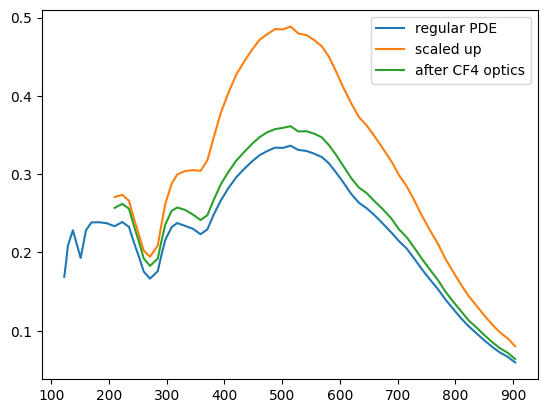

In [5]:
# print(type(tt))
# print(tt.keys())
# np = tt.arrays("fNphoton")
# tt.num_entries


wlPDE, pde = np.loadtxt(os.path.join(opticsPath, "SiPMeff_Ham_5V.dat"), skiprows=1, unpack = True)
pde *= 1/100

start = 9
pdeScaledUp = pde[start:]/fairEff_0(wlPDE[start:])
pdeScaledBack = pdeScaledUp*fcf4Eff_0(wlPDE[start:])  

# are the optics dominated by the thin film or the bulk                         

plt.plot(wlPDE, pde, label = "regular PDE")
plt.plot(wlPDE[start:], pdeScaledUp, label = "scaled up")
plt.plot(wlPDE[start:], pdeScaledBack, label = "after CF4 optics")
plt.legend()

plt.show()